Epoch 1/20


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 920ms/step - accuracy: 0.5000 - loss: 0.6931
Epoch 2/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.5000 - loss: 0.6931
Epoch 3/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.5000 - loss: 0.6931
Epoch 4/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step - accuracy: 0.5000 - loss: 0.6931
Epoch 5/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step - accuracy: 0.5000 - loss: 0.6931
Epoch 6/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.5000 - loss: 0.6931
Epoch 7/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - accuracy: 0.5000 - loss: 0.6931
Epoch 8/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step - accuracy: 0.5000 - loss: 0.6931
Epoch 9/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.5000 - loss: 0.6931
Epoch 10/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.5000 - loss: 0.6931
Epoch 11/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step - accuracy: 0.5000 - loss: 0.6931
Epoch 12/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step - accuracy: 0.5000 - loss: 0.6931
Epoch 

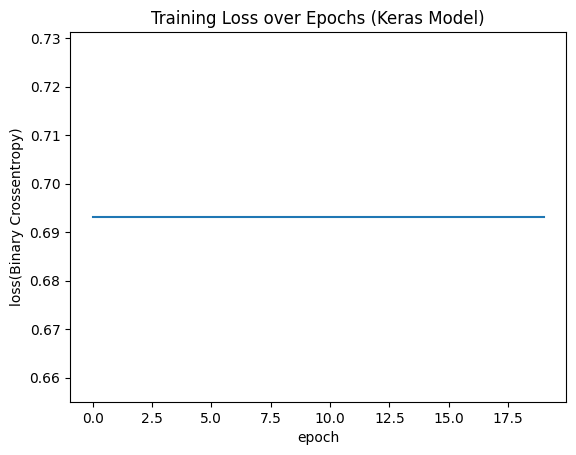

In [1]:
import numpy as np
import tensorflow
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
x=np.array([[0,0],[0,1],[1,0],[1,1]])
y=np.array([[0],[1],[1],[0]])
input_size=2
hidden_size=2
output_size=1
epochs=20
model=Sequential([
Dense(hidden_size, input_dim=input_size, activation='relu'),Dense(output_size, activation='sigmoid')])
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
history=model.fit(x, y, epochs=epochs, verbose=1)
print("Training complete")
print("\n---Model's Learned Input-Output Sequence---")
print("Input  | Correct | Model's")
print("       | Answer  | Prediction(raw) | Prediction(clean)")

print("-"*30)
predictions_raw=model.predict(x, verbose=1)
for i in range(len(x)):
    input_pair=x[i]
    correct_answer=y[i][0]





    predicted_raw=predictions_raw[i][0]
    predicted_clean=(predicted_raw>0.5).astype(int)
    inp_str=f"[{input_pair[0]}, {input_pair[1]}]"
    print(f"{inp_str} |  {correct_answer}  |   {predicted_raw:.4f}    |      {predicted_clean}")
loss_history=history.history['loss']
plt.plot(range(epochs), loss_history)
plt.xlabel("epoch")
plt.ylabel("loss(Binary Crossentropy)")
plt.title("Training Loss over Epochs (Keras Model)")
plt.show()



In [3]:
import tensorflow_hub as hub
import tensorflow as tf
import numpy as np
import PIL.Image
print("Loading model...")
generator=hub.load("https://tfhub.dev/google/progan-128/1").signatures['default']
print("Model Loaded.")
noise=np.random.normal(size=[1,512])
generated_image=generator(tf.constant(noise,dtype=tf.float32))['default']
generated_image=(generated_image.numpy().squeeze()+1)*127.5
generated_image=np.uint8(generated_image)
img=PIL.Image.fromarray(generated_image)
img.save("new_face.png")
print("New image saved as 'new_face.png'")

/usr/local/lib/python3.13/dist-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


Loading model...
Model Loaded.
New image saved as 'new_face.png'
